# ML Mini Project: Kickstarter success prediction (reproduce and extend)
Run the cells from top to bottom.

## 1. Imports

In [1]:
import glob, json, ast, os, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge, Lasso, LinearRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

## 2. Settings and reported numbers from the paper

In [2]:
SEED = 42
MIN_COUNT = 1000
RIDGE_ALPHA = 0.75
LASSO_ALPHA = 0.001
CATS = ["currency", "country", "category", "parent", "location", "loctype"]
COLS = ["name", "blurb", "goal", "static_usd_rate", "currency", "country",
        "category", "location", "launched_at", "deadline", "state"]
METRIC_NAMES = ["A", "F1", "P1", "P0", "R1", "R0"]

REPORTED = {
    1: {"G. Boosting": (0.81, 0.83, 0.90, 0.72, 0.77, 0.88),
        "R. Forest": (0.80, 0.82, 0.91, 0.70, 0.74, 0.89),
        "Neural Net": (0.80, 0.82, 0.90, 0.70, 0.75, 0.88),
        "SVM": (0.79, 0.83, 0.81, 0.74, 0.84, 0.71),
        "Logistic": (0.78, 0.80, 0.88, 0.67, 0.72, 0.86),
        "Ridge": (0.77, 0.79, 0.90, 0.66, 0.70, 0.88),
        "OLS": (0.77, 0.79, 0.90, 0.66, 0.70, 0.88),
        "Lasso": (0.70, 0.74, 0.78, 0.61, 0.70, 0.71)},
    2: {"G. Boosting": (0.83, 0.85, 0.89, 0.75, 0.81, 0.84),
        "Neural Net": (0.82, 0.84, 0.88, 0.74, 0.80, 0.84),
        "R. Forest": (0.82, 0.84, 0.88, 0.74, 0.80, 0.84),
        "Logistic": (0.80, 0.83, 0.86, 0.72, 0.79, 0.80),
        "SVM": (0.80, 0.83, 0.82, 0.76, 0.85, 0.71),
        "Ridge": (0.80, 0.82, 0.87, 0.71, 0.77, 0.83),
        "OLS": (0.80, 0.82, 0.87, 0.71, 0.77, 0.83),
        "Lasso": (0.71, 0.75, 0.79, 0.62, 0.72, 0.71)},
}

## 3. Download the data
This tries to find the CSV zip links on the Web Robots page (Apr 2019 to Apr 2021) and prints them. Check the list looks right. If it finds nothing, paste the links yourself into `MANUAL_LINKS` (right click each CSV zip on the site, copy link address).

In [3]:
MANUAL_LINKS = []

PAGE = "https://webrobots.io/kickstarter-datasets/"
links = []
if not MANUAL_LINKS:
    html = requests.get(PAGE, timeout=60).text
    found = sorted(set(re.findall(r"https?://[^\"'\s<>]+\.zip", html)))
    found = [u for u in found if "json" not in u.lower()]
    for u in found:
        m = re.search(r"Kickstarter_(\d{4})-(\d{2})", u)
        if m and (2019, 4) <= (int(m.group(1)), int(m.group(2))) <= (2021, 4):
            links.append(u)
urls = MANUAL_LINKS or links
print(len(urls), "links")
for u in urls:
    print(u)

24 links
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-05-16T03_20_20_822Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-06-13T03_20_35_801Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-07-18T03_20_05_009Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-08-15T03_20_03_022Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-09-12T03_20_06_215Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-10-17T03_20_19_421Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-11-14T03_20_27_004Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-12-12T03_20_05_306Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2020-01-16T03_20_15_556Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2020-02-13T03_20_04_893Z.zip
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2020-03-

In [5]:
os.makedirs("zips", exist_ok=True)
os.makedirs("data", exist_ok=True)
failed = []
for u in urls:
    name = os.path.basename(u.split("?")[0])
    zpath = os.path.join("zips", name)
    if not os.path.exists(zpath):
        try:
            with requests.get(u, stream=True, timeout=300, headers={"User-Agent": "Mozilla/5.0"}) as r:
                r.raise_for_status()
                with open(zpath, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
        except Exception as e:
            failed.append(u)
            if os.path.exists(zpath):
                os.remove(zpath)
            continue

for zpath in sorted(glob.glob("zips/*.zip")):
    name = os.path.basename(zpath)
    out = os.path.join("data", name[:-4])
    if not os.path.exists(out):
        with zipfile.ZipFile(zpath) as z:
            z.extractall(out)

print(len(glob.glob("data/**/*.csv", recursive=True)), "csv files")
print(len(failed), "downloads failed")
for u in failed:
    print(u)

1335 csv files
1 downloads failed
https://s3.amazonaws.com/weruns/forfun/Kickstarter/Kickstarter_2019-05-16T03_20_20_822Z.zip


## 4. Load and clean (same as common.py)

In [7]:
def parse(x):
    if isinstance(x, dict):
        return x
    if not isinstance(x, str):
        return {}
    try:
        return json.loads(x)
    except Exception:
        try:
            return ast.literal_eval(x)
        except Exception:
            return {}


def load_raw(path="data"):
    files = sorted(glob.glob(f"{path}/**/*.csv", recursive=True))
    df = None
    for f in files:
        part = pd.read_csv(f, usecols=lambda c: c in COLS)
        part = part[part.state.isin(["successful", "failed"])]
        df = part if df is None else pd.concat([df, part], ignore_index=True)
        df = df.drop_duplicates(subset=["name", "blurb", "launched_at", "deadline"])
    return df.reset_index(drop=True)


def clean(df):
    cat = df.category.map(parse)
    loc = df.location.map(parse)
    out = pd.DataFrame(index=df.index)
    out["y"] = (df.state == "successful").astype(int)
    out["goal"] = df.goal * df.static_usd_rate
    out["category"] = cat.map(lambda d: d.get("name", "na"))
    out["parent"] = cat.map(lambda d: d.get("slug", "na/na").split("/")[0])
    out["location"] = loc.map(lambda d: d.get("name", "na"))
    out["loctype"] = loc.map(lambda d: d.get("type", "na"))
    out["country"] = df.country.fillna("na")
    out["currency"] = df.currency.fillna("na")
    out["blurb"] = df.blurb.fillna("")
    out["blurb_len"] = out.blurb.str.len()
    out["name_len"] = df.name.fillna("").str.len()
    out["duration"] = (df.deadline - df.launched_at) / 86400
    launched = pd.to_datetime(df.launched_at, unit="s")
    out["launch_month"] = launched.dt.month
    out["launch_year"] = launched.dt.year
    return out


raw = load_raw()
data_all = clean(raw)
del raw
print(data_all.shape)
print(data_all.y.value_counts())
data_all.describe()

(220003, 14)
y
1    131829
0     88174
Name: count, dtype: int64


,y,goal,blurb_len,name_len,duration,launch_month,launch_year
count,220003.000000,2.200030e+05,220003.000000,220003.000000,220003.000000,220003.000000,220003.000000
mean,0.599215,3.674928e+04,107.476821,34.716122,32.692087,6.392540,2016.518266
std,0.490059,1.034052e+06,30.208772,15.637782,12.093132,3.367964,2.505896
min,0.000000,1.000000e-02,0.000000,1.000000,1.000000,1.000000,2009.000000
25%,0.000000,1.377811e+03,91.000000,22.000000,29.958333,3.000000,2015.000000
50%,1.000000,4.857330e+03,120.000000,34.000000,30.000000,6.000000,2017.000000
75%,1.000000,1.200100e+04,131.000000,48.000000,34.958333,9.000000,2019.000000
max,1.000000,1.523501e+08,196.000000,85.000000,120.589687,12.000000,2021.000000


## 5. Features: target encodings, one-hot, Naive Bayes

In [8]:
def fit_map(c, y, g):
    d = pd.DataFrame({"c": c.values, "y": y.values, "g": g.values})
    a = d.groupby("c").agg(n=("y", "size"), ym=("y", "mean"), gm=("g", "mean"))
    a = a[a.n >= MIN_COUNT]
    return a.ym, a.gm, y.mean(), g.mean()


def apply_map(c, m):
    ym, gm, y0, g0 = m
    return c.map(ym).fillna(y0).values, c.map(gm).fillna(g0).values


def encode(tr, te):
    kf = KFold(5, shuffle=True, random_state=SEED)
    ftr, fte = {}, {}
    for col in CATS:
        a = np.zeros(len(tr))
        b = np.zeros(len(tr))
        for i, j in kf.split(tr):
            m = fit_map(tr[col].iloc[i], tr.y.iloc[i], tr.goal.iloc[i])
            a[j], b[j] = apply_map(tr[col].iloc[j], m)
        m = fit_map(tr[col], tr.y, tr.goal)
        c, d = apply_map(te[col], m)
        ftr[f"{col}_ym"], ftr[f"{col}_gm"], ftr[f"{col}_gd"] = a, b, tr.goal.values - b
        fte[f"{col}_ym"], fte[f"{col}_gm"], fte[f"{col}_gd"] = c, d, te.goal.values - d
    return pd.DataFrame(ftr, index=tr.index), pd.DataFrame(fte, index=te.index)


def nb_feature(tr, te):
    def make():
        return make_pipeline(
            TfidfVectorizer(stop_words="english", min_df=10, max_df=0.35),
            MultinomialNB())
    kf = KFold(5, shuffle=True, random_state=SEED)
    oof = cross_val_predict(make(), tr.blurb, tr.y, cv=kf, method="predict_proba")[:, 1]
    full = make().fit(tr.blurb, tr.y)
    return oof, full.predict_proba(te.blurb)[:, 1]


tr, te = train_test_split(data_all, test_size=0.3, random_state=SEED)
etr, ete = encode(tr, te)
num = ["goal", "blurb_len", "name_len", "duration", "launch_month", "launch_year"]
oh = pd.get_dummies(pd.concat([tr, te])[["category", "parent"]]).astype(int)
xtr = pd.concat([tr[num], etr, oh.loc[tr.index]], axis=1)
xte = pd.concat([te[num], ete, oh.loc[te.index]], axis=1)
nbtr, nbte = nb_feature(tr, te)
xtr2, xte2 = xtr.copy(), xte.copy()
xtr2["nb"], xte2["nb"] = nbtr, nbte
data = {1: (xtr, xte), 2: (xtr2, xte2), "y": (tr.y.values, te.y.values)}
print("total", len(data_all), "train", len(tr), "test", len(te))
print("features sample 1:", xtr.shape[1], "sample 2:", xtr2.shape[1])

total 220003 train 154002 test 66001
features sample 1: 200 sample 2: 201


## 6. Models from the paper (same as reproduce.py)

In [9]:
def metrics(y, p):
    return [accuracy_score(y, p), f1_score(y, p), precision_score(y, p),
            precision_score(y, p, pos_label=0), recall_score(y, p),
            recall_score(y, p, pos_label=0)]


def models():
    return {
        "G. Boosting": (LGBMClassifier(n_estimators=500, learning_rate=0.05, max_depth=55,
                                       num_leaves=400, subsample=0.75, subsample_freq=1,
                                       colsample_bytree=0.2, max_bin=500,
                                       class_weight="balanced", random_state=SEED,
                                       verbose=-1), False),
        "R. Forest": (RandomForestClassifier(n_estimators=200, max_depth=55,
                                             min_samples_leaf=10, max_features=15,
                                             criterion="gini", class_weight="balanced",
                                             n_jobs=-1, random_state=SEED), False),
        "Neural Net": (Pipeline([("s", StandardScaler()),
                                 ("m", MLPClassifier(hidden_layer_sizes=(25,),
                                                     activation="relu", solver="adam",
                                                     batch_size=256, max_iter=30,
                                                     random_state=SEED))]), False),
        "SVM": (Pipeline([("s", MinMaxScaler()),
                          ("m", LinearSVC(C=1, loss="squared_hinge", class_weight="balanced",
                                          max_iter=5000, random_state=SEED))]), False),
        "Logistic": (Pipeline([("s", StandardScaler()),
                               ("m", LogisticRegression(C=0.1, class_weight="balanced",
                                                        max_iter=1000))]), False),
        "Ridge": (Pipeline([("s", StandardScaler()), ("m", Ridge(alpha=RIDGE_ALPHA))]), True),
        "OLS": (Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), True),
        "Lasso": (Pipeline([("s", StandardScaler()), ("m", Lasso(alpha=LASSO_ALPHA))]), True),
    }


def run(sample):
    xa, xb = data[sample]
    ya, yb = data["y"]
    w = compute_sample_weight("balanced", ya)
    rows = []
    for name, (model, reg) in models().items():
        if reg:
            model.fit(xa, ya, m__sample_weight=w)
            pred = (model.predict(xb) > 0.5).astype(int)
        else:
            model.fit(xa, ya)
            pred = model.predict(xb)
        rows.append([sample, name] + metrics(yb, pred))
        print(sample, name, np.round(rows[-1][2:], 3))
    return rows

## 7. Part 1: run the reproduction and compare with the paper

In [10]:
rows = run(1) + run(2)
res = pd.DataFrame(rows, columns=["sample", "model"] + METRIC_NAMES).round(3)
res.to_csv("results_reproduced.csv", index=False)

1 G. Boosting [0.808 0.832 0.876 0.728 0.792 0.832]
1 R. Forest [0.797 0.817 0.888 0.701 0.757 0.857]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


1 Neural Net [0.805 0.832 0.864 0.731 0.802 0.811]
1 SVM [0.766 0.783 0.883 0.659 0.704 0.86 ]
1 Logistic [0.775 0.792 0.887 0.67  0.716 0.862]
1 Ridge [0.734 0.749 0.862 0.624 0.662 0.841]
1 OLS [0.734 0.749 0.862 0.624 0.662 0.841]
1 Lasso [0.764 0.778 0.894 0.653 0.689 0.877]
2 G. Boosting [0.821 0.844 0.886 0.743 0.806 0.844]
2 R. Forest [0.807 0.828 0.889 0.717 0.776 0.854]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


2 Neural Net [0.817 0.845 0.859 0.758 0.831 0.796]
2 SVM [0.785 0.804 0.888 0.683 0.734 0.861]
2 Logistic [0.791 0.81  0.89  0.692 0.744 0.862]
2 Ridge [0.748 0.765 0.868 0.64  0.684 0.844]
2 OLS [0.748 0.765 0.868 0.64  0.684 0.844]
2 Lasso [0.779 0.794 0.899 0.67  0.711 0.88 ]


In [11]:
comp = []
for _, r in res.iterrows():
    rep = REPORTED[r["sample"]][r["model"]]
    comp.append([r["sample"], r["model"], rep[0], r["A"], round(r["A"] - rep[0], 3),
                 rep[1], r["F1"], round(r["F1"] - rep[1], 3)])
comp = pd.DataFrame(comp, columns=["sample", "model", "A_reported", "A_mine", "A_diff",
                                   "F1_reported", "F1_mine", "F1_diff"])
comp.to_csv("comparison.csv", index=False)
display(comp[comp["sample"] == 1])
display(comp[comp["sample"] == 2])

,sample,model,A_reported,A_mine,A_diff,F1_reported,F1_mine,F1_diff
0,1,G. Boosting,0.81,0.808,-0.002,0.83,0.832,0.002
1,1,R. Forest,0.80,0.797,-0.003,0.82,0.817,-0.003
2,1,Neural Net,0.80,0.805,0.005,0.82,0.832,0.012
3,1,SVM,0.79,0.766,-0.024,0.83,0.783,-0.047
4,1,Logistic,0.78,0.775,-0.005,0.80,0.792,-0.008
5,1,Ridge,0.77,0.734,-0.036,0.79,0.749,-0.041
6,1,OLS,0.77,0.734,-0.036,0.79,0.749,-0.041
7,1,Lasso,0.70,0.764,0.064,0.74,0.778,0.038


,sample,model,A_reported,A_mine,A_diff,F1_reported,F1_mine,F1_diff
8,2,G. Boosting,0.83,0.821,-0.009,0.85,0.844,-0.006
9,2,R. Forest,0.82,0.807,-0.013,0.84,0.828,-0.012
10,2,Neural Net,0.82,0.817,-0.003,0.84,0.845,0.005
11,2,SVM,0.80,0.785,-0.015,0.83,0.804,-0.026
12,2,Logistic,0.80,0.791,-0.009,0.83,0.810,-0.020
13,2,Ridge,0.80,0.748,-0.052,0.82,0.765,-0.055
14,2,OLS,0.80,0.748,-0.052,0.82,0.765,-0.055
15,2,Lasso,0.71,0.779,0.069,0.75,0.794,0.044


### Graphs: reported vs mine

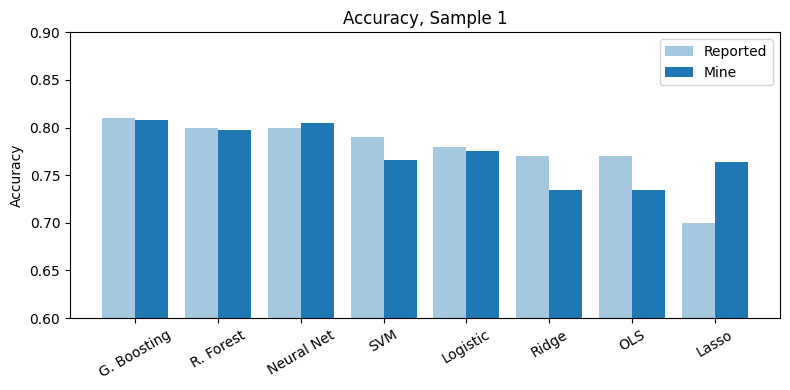

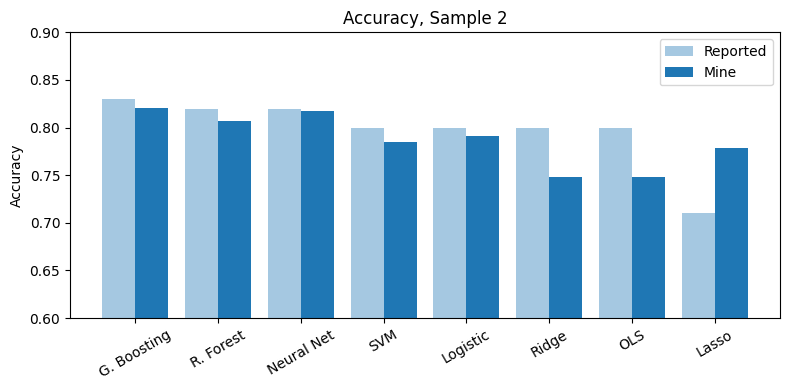

In [12]:
for s in (1, 2):
    c = comp[comp["sample"] == s]
    x = np.arange(len(c))
    plt.figure(figsize=(8, 4))
    plt.bar(x - 0.2, c.A_reported, 0.4, color="tab:blue", alpha=0.4, label="Reported")
    plt.bar(x + 0.2, c.A_mine, 0.4, color="tab:blue", label="Mine")
    plt.xticks(x, c.model, rotation=30)
    plt.ylabel("Accuracy")
    plt.ylim(0.6, 0.9)
    plt.title(f"Accuracy, Sample {s}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"reproduce_sample{s}.png", dpi=150)
    plt.show()

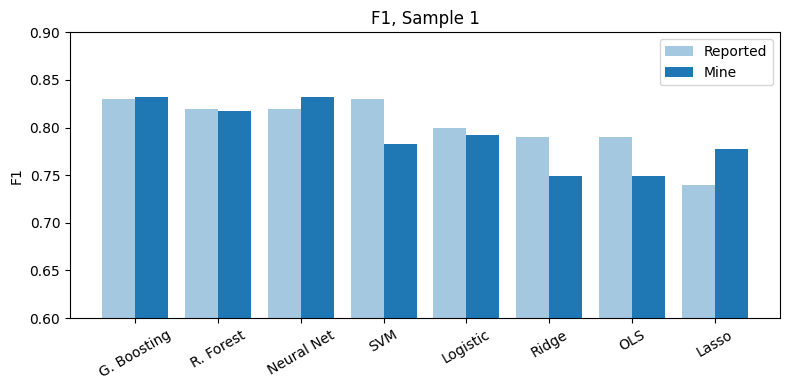

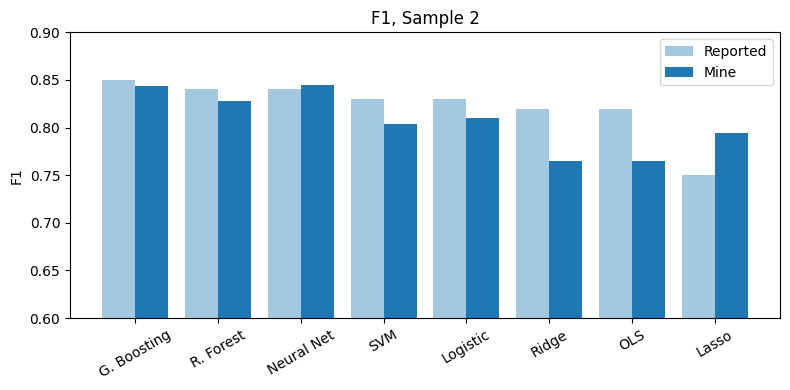

In [13]:
for s in (1, 2):
    c = comp[comp["sample"] == s]
    x = np.arange(len(c))
    plt.figure(figsize=(8, 4))
    plt.bar(x - 0.2, c.F1_reported, 0.4, color="tab:blue", alpha=0.4, label="Reported")
    plt.bar(x + 0.2, c.F1_mine, 0.4, color="tab:blue", label="Mine")
    plt.xticks(x, c.model, rotation=30)
    plt.ylabel("F1")
    plt.ylim(0.6, 0.9)
    plt.title(f"F1, Sample {s}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"reproduce_f1_sample{s}.png", dpi=150)
    plt.show()

## 8. Part 2: extra model (XGBoost)

In [14]:
ya, yb = data["y"]
spw = (ya == 0).sum() / (ya == 1).sum()
rows = []
for s in (1, 2):
    xa, xb = data[s]
    m = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=10, subsample=0.75,
                      colsample_bytree=0.5, min_child_weight=5, reg_lambda=1.0,
                      tree_method="hist", scale_pos_weight=spw, n_jobs=-1,
                      random_state=SEED, eval_metric="logloss")
    m.fit(xa, ya)
    rows.append([s, "XGBoost"] + metrics(yb, m.predict(xb)))
new = pd.DataFrame(rows, columns=["sample", "model"] + METRIC_NAMES).round(3)
allres = pd.concat([res, new], ignore_index=True)
allres.to_csv("results_all.csv", index=False)
display(allres[allres["sample"] == 1].sort_values("A", ascending=False))
display(allres[allres["sample"] == 2].sort_values("A", ascending=False))

,sample,model,A,F1,P1,P0,R1,R0
16,1,XGBoost,0.811,0.831,0.897,0.719,0.775,0.867
0,1,G. Boosting,0.808,0.832,0.876,0.728,0.792,0.832
2,1,Neural Net,0.805,0.832,0.864,0.731,0.802,0.811
1,1,R. Forest,0.797,0.817,0.888,0.701,0.757,0.857
4,1,Logistic,0.775,0.792,0.887,0.670,0.716,0.862
3,1,SVM,0.766,0.783,0.883,0.659,0.704,0.860
7,1,Lasso,0.764,0.778,0.894,0.653,0.689,0.877
6,1,OLS,0.734,0.749,0.862,0.624,0.662,0.841
5,1,Ridge,0.734,0.749,0.862,0.624,0.662,0.841


,sample,model,A,F1,P1,P0,R1,R0
17,2,XGBoost,0.823,0.844,0.897,0.739,0.797,0.863
8,2,G. Boosting,0.821,0.844,0.886,0.743,0.806,0.844
10,2,Neural Net,0.817,0.845,0.859,0.758,0.831,0.796
9,2,R. Forest,0.807,0.828,0.889,0.717,0.776,0.854
12,2,Logistic,0.791,0.810,0.890,0.692,0.744,0.862
11,2,SVM,0.785,0.804,0.888,0.683,0.734,0.861
15,2,Lasso,0.779,0.794,0.899,0.670,0.711,0.880
14,2,OLS,0.748,0.765,0.868,0.640,0.684,0.844
13,2,Ridge,0.748,0.765,0.868,0.640,0.684,0.844


### Graphs: all models including XGBoost

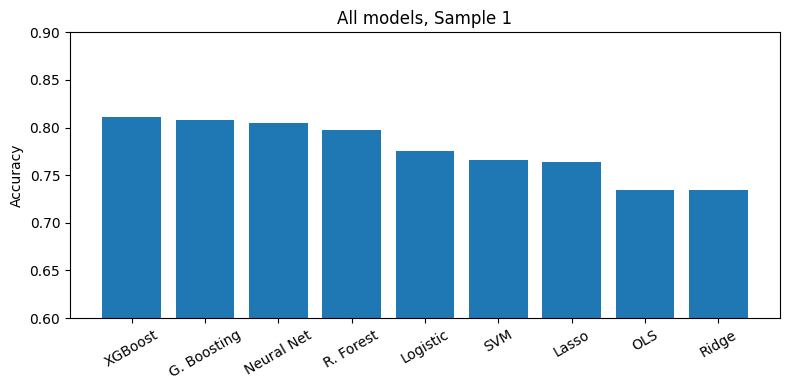

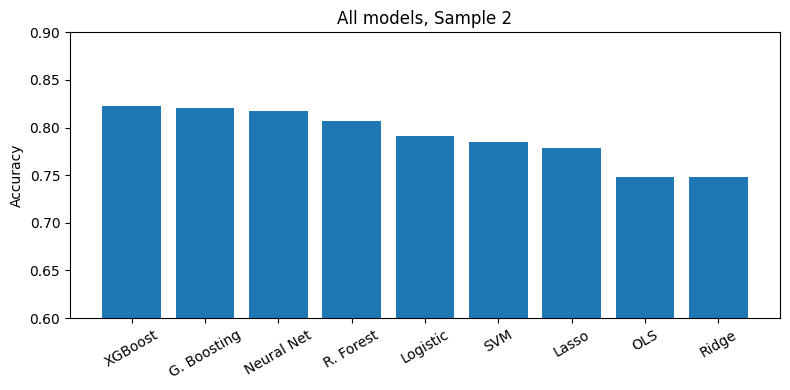

In [15]:
for s in (1, 2):
    c = allres[allres["sample"] == s].sort_values("A", ascending=False)
    plt.figure(figsize=(8, 4))
    plt.bar(c.model, c.A, color="tab:blue")
    plt.xticks(rotation=30)
    plt.ylabel("Accuracy")
    plt.ylim(0.6, 0.9)
    plt.title(f"All models, Sample {s}")
    plt.tight_layout()
    plt.savefig(f"extend_sample{s}.png", dpi=150)
    plt.show()

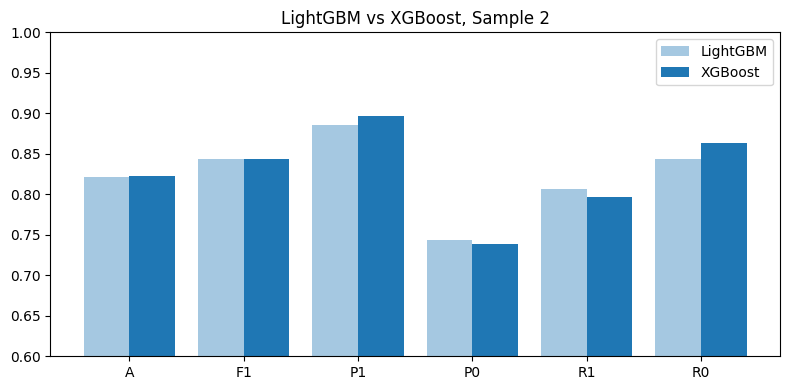

In [16]:
cmp = allres[allres.model.isin(["G. Boosting", "XGBoost"])]
x = np.arange(len(METRIC_NAMES))
plt.figure(figsize=(8, 4))
lg = cmp[(cmp["sample"] == 2) & (cmp.model == "G. Boosting")][METRIC_NAMES].values[0]
xg = cmp[(cmp["sample"] == 2) & (cmp.model == "XGBoost")][METRIC_NAMES].values[0]
plt.bar(x - 0.2, lg, 0.4, color="tab:blue", alpha=0.4, label="LightGBM")
plt.bar(x + 0.2, xg, 0.4, color="tab:blue", label="XGBoost")
plt.xticks(x, METRIC_NAMES)
plt.ylim(0.6, 1.0)
plt.title("LightGBM vs XGBoost, Sample 2")
plt.legend()
plt.tight_layout()
plt.savefig("lgbm_vs_xgb.png", dpi=150)
plt.show()

## 9. Download the outputs

In [17]:
from google.colab import files
for f in ["comparison.csv", "results_all.csv", "reproduce_sample1.png", "reproduce_sample2.png",
          "reproduce_f1_sample1.png", "reproduce_f1_sample2.png", "extend_sample1.png",
          "extend_sample2.png", "lgbm_vs_xgb.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>